# 01. EDA(探索的データ分析)

**このノートブックの目的:** データの偏りを調べ、特徴量エンジニアリング(03)の着想を得る。

**結論:** EDAから仮説が2つ生まれた。それぞれをEDAで確かめ、特徴量を作った。

| 仮説 | 生まれた節 | 確かめた節 | 作った特徴量 |
|---|---|---|---|
| ① Flight Distanceの効き目は、「出張かつビジネスクラス」という客層の違いの表れではないか | 1・2節 | 3節: 私用客はサービス評価に関係なく満足率が約10%。4節: 常連でない客にも快適さが効かない | 出張客だけに評価の値を持たせるゲート特徴量(出張客の快適さ・出張客のOn-board service・常連かつ出張客の快適さ(SHAPで1位))、Flight Distance×Classの満足率 |
| ② Inflight wifi serviceなどの0点は、最低評価ではなく「評価なし」ではないか | 5節 | 6節: Inflight wifi service・Ease of Online booking・Online boardingの0点は「評価なし」、Seat comfort・Food and drinkなどの0点は最低評価で、項目で意味が違う | 0点の印(効かなかった。木は1回の分岐で0点を区別できるため) |

## 準備

- ライブラリを読み込み、trainを読み込む。
- 特徴量を数値(`NUM`)・カテゴリ(`CAT`)・サービス評価13項目(`SVC`)に分ける。
- `LOG`: 遅延の2つは約9割が0分で、全行で描くと0に潰れるので、グラフでは0分より長い行だけを対数(log1p)で描く。`PAL`: グラフの満足/不満の色。

In [1]:
import numpy as np  # 数値の配列の計算
import pandas as pd  # 表の読み込みと集計
import matplotlib.pyplot as plt  # グラフを描く
import seaborn as sns  # グラフを描く(matplotlibの補助)

plt.rcParams["font.family"] = "Meiryo"  # グラフの日本語ラベル用
train = pd.read_csv("../data/train.csv")  # data/ の train.csv を読み込む
TARGET = "satisfaction"  # 目的変数の列名
NUM = ["Age", "Flight Distance", "Departure Delay in Minutes", "Arrival Delay in Minutes"]  # 数値の特徴量4個
CAT = ["Gender", "Customer Type", "Type of Travel", "Class"]  # カテゴリの特徴量4個
SVC = [c for c in train.columns if c not in NUM + CAT + ["id", TARGET]]  # サービス評価0〜5の13項目
LOG = {"Departure Delay in Minutes", "Arrival Delay in Minutes"}  # 約9割が0で潰れるため、遅延>0の行だけをlog1pで描く
PAL = {False: "#4C72B0", True: "#DD8452"}  # グラフの色(不満=青、満足=橙)
print(train.shape, train[TARGET].mean())  # 行数・列数と満足の割合を確かめる

(699635, 23) 0.44357272006117476


## 1節 数値変数 × 満足度(箱ひげ図・ヒストグラム)

#### ① 目的・仮説
- **確認したいこと:** 数値の特徴量(Age・Flight Distance・遅延)の値によって、満足率がどう変わるか。
- **なぜ必要か:** 値の範囲ごとの満足率の変わり方(急な段差・山型)は、特徴量の作り方の手がかりになる。
- **想定する結果:** 遅延が長いほど満足率が下がる。Flight Distance・Ageは、ゆるやかに効く。

#### ② 検証方法
- **データ:** train。
- **方法:** 特徴量ごとに、満足/不満で分けた箱ひげ図と、値の分布(満足/不満それぞれの中での割合)を並べる。

#### ③ コード・実行結果

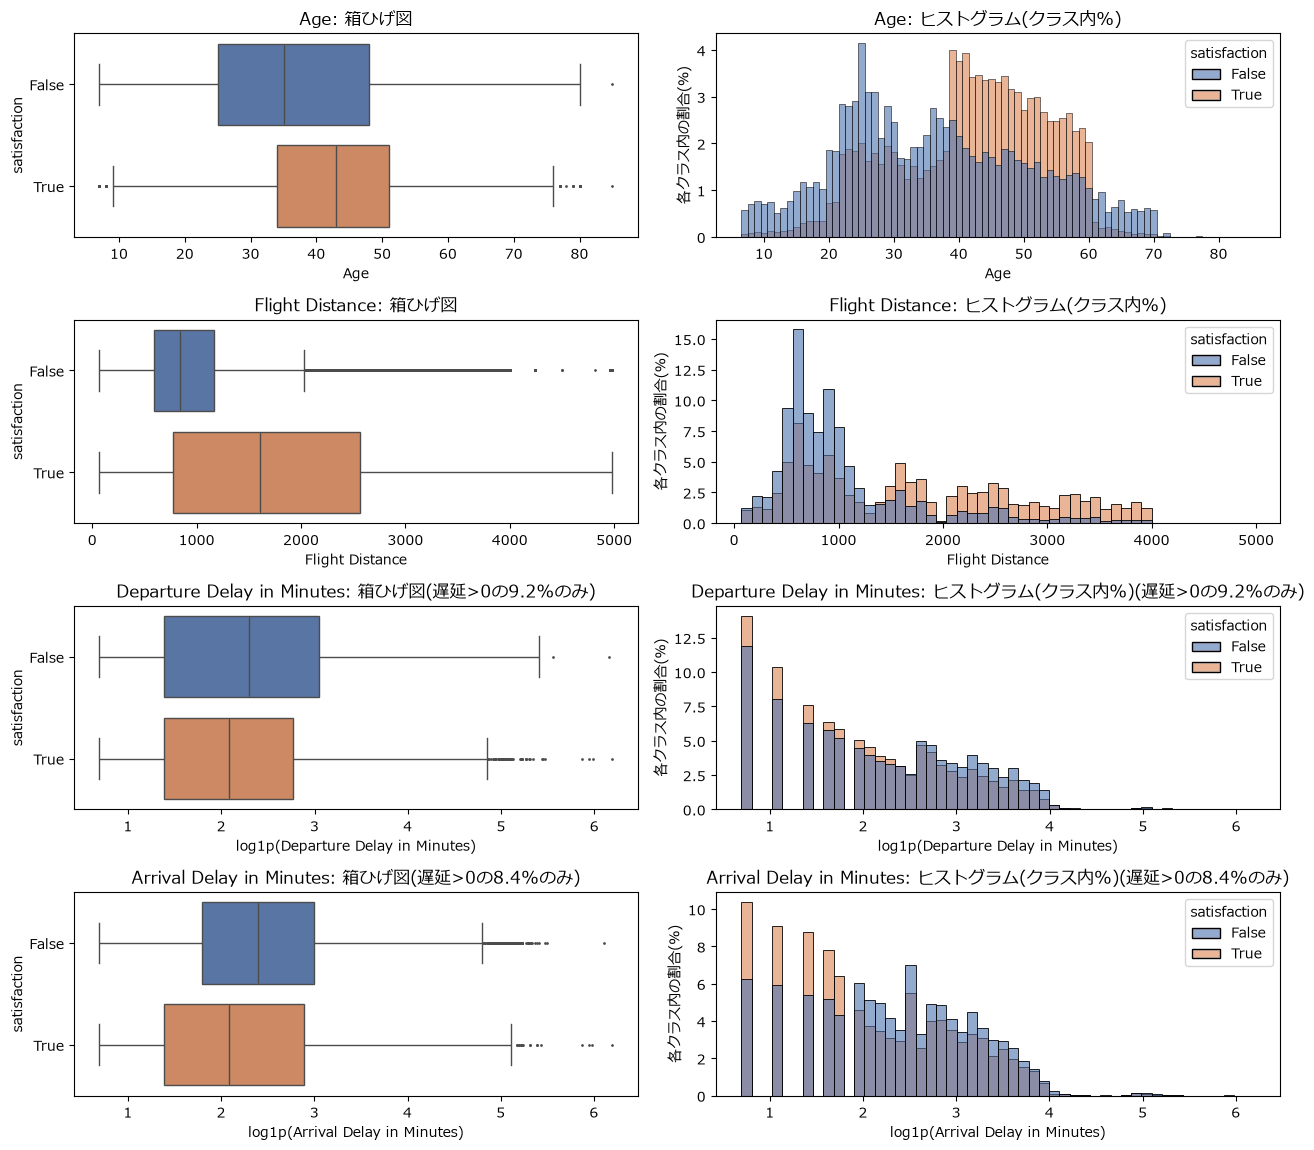

In [3]:
def box_hist(cols, discrete=()):
    """各変数について、左に満足度別の箱ひげ図、右に満足度別のヒストグラム(Class内の割合)を並べる。"""
    fig, axes = plt.subplots(len(cols), 2, figsize=(13, 2.9 * len(cols)))
    for (ax_b, ax_h), c in zip(axes, cols):
        sub = train[train[c] > 0] if c in LOG else train
        x = np.log1p(sub[c]) if c in LOG else sub[c]
        label = f"log1p({c})" if c in LOG else c
        note = f"(遅延>0の{len(sub) / len(train):.1%}のみ)" if c in LOG else ""
        d = pd.DataFrame({label: x, TARGET: sub[TARGET]})
        disc = c in discrete
        sns.boxplot(data=d, x=label, y=TARGET, orient="h", order=[False, True],
                    hue=TARGET, palette=PAL, legend=False, ax=ax_b, fliersize=1)
        ax_b.set_title(f"{c}: 箱ひげ図{note}")
        # 満足/不満でサンプル数が違う(44%/56%)ので、各Class内の割合で形を比べる
        sns.histplot(data=d, x=label, hue=TARGET, palette=PAL, stat="percent", common_norm=False,
                     discrete=disc, bins="auto" if disc else 50, multiple="dodge" if disc and c not in ("Age",) else "layer",
                     shrink=0.8 if disc and c != "Age" else 1, element="bars", alpha=0.6, ax=ax_h)
        ax_h.set_title(f"{c}: ヒストグラム(クラス内%){note}")
        ax_h.set_ylabel("各クラス内の割合(%)")
    fig.tight_layout()
    plt.show()

box_hist(NUM, discrete=("Age",))

#### ④ 考察・次のアクション
- **読み取れること:**
  - Flight Distance: 満足の中央値は1,605、不満は841。満足率は1,500付近を境に、約30%から66〜77%へ急に上がる(単変量AUC 0.696)。
  - Age: 満足率は40〜60歳だけが約60%と高い山型(〜20歳は16%、61歳〜は14%)。
  - 遅延: 約9割が0分。遅延が長いほど満足率は下がる(Arrival Delay in Minutes 0分で45%、16〜60分で31%)が、全体を分ける力は弱い(AUC約0.49)。
- **想定との比較:** 遅延は想定どおりの向きだったが、効き方は弱かった。Flight Distanceは想定と違い、ゆるやかではなく急な段差があった。
- **次のアクション:** Flight Distanceの急な段差は、「長距離便=出張でビジネスクラス」という客層の違いの表れではないか(仮説①)。2節でカテゴリも見たうえで、3節で確かめる。

## 2節 カテゴリ変数 × 満足度(件数・満足率)

#### ① 目的・仮説
- **確認したいこと:** カテゴリの特徴量(Class・Type of Travel・Customer Type・Gender)ごとに、満足率にどれだけ差があるか。
- **なぜ必要か:** 1節で見たFlight Distanceの段差が、客層の違いで説明できるかの手がかりになる。
- **想定する結果:** ビジネスクラス・出張の客は満足率が高い。Genderでは差がない。

#### ② 検証方法
- **データ:** train。
- **方法:** カテゴリごとに、件数と満足率を並べる(満足率の点線は全体の44.4%)。

#### ③ コード・実行結果

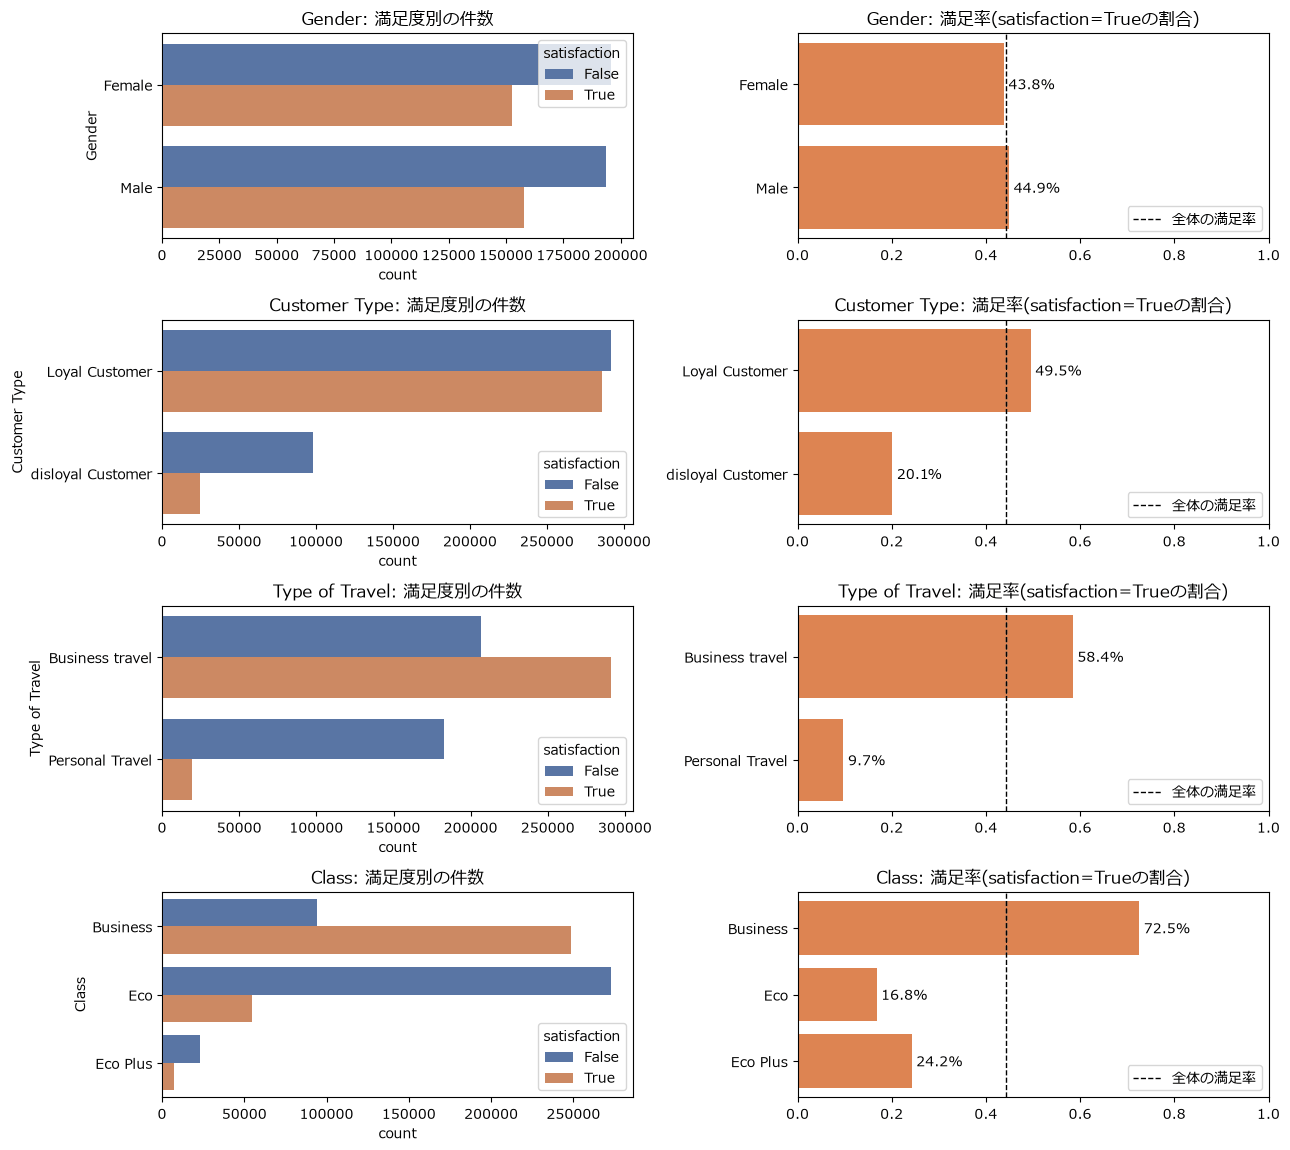

In [4]:
# カテゴリ変数は数値でないため箱ひげ図は描けない。代わりに満足度別の件数(ヒストグラム相当)と満足率を並べる
fig, axes = plt.subplots(len(CAT), 2, figsize=(13, 2.9 * len(CAT)))
for (ax_c, ax_r), c in zip(axes, CAT):
    order = sorted(train[c].unique())
    sns.countplot(data=train, y=c, hue=TARGET, palette=PAL, order=order, ax=ax_c)
    ax_c.set_title(f"{c}: 満足度別の件数")
    rate = train.groupby(c)[TARGET].mean().reindex(order)
    ax_r.barh(order, rate.values, color="#DD8452")
    ax_r.axvline(train[TARGET].mean(), color="k", ls="--", lw=1, label="全体の満足率")
    for i, v in enumerate(rate.values):
        ax_r.text(v + 0.01, i, f"{v:.1%}", va="center")
    ax_r.set_xlim(0, 1); ax_r.invert_yaxis(); ax_r.legend(loc="lower right")
    ax_r.set_title(f"{c}: 満足率(satisfaction=Trueの割合)")
fig.tight_layout()
plt.show()

#### ④ 考察・次のアクション
- **読み取れること:** 満足率はClassでBusiness 72.5%、Eco 16.8%、Eco Plus 24.2%。Type of Travelで出張58.4%、私用9.7%。常連で49.5%、常連でない客で20.1%。Genderではほぼ差がない。
- **想定との比較:** 想定どおりだった。ClassとType of Travelの差は、Flight Distanceの段差と同じくらい大きい。
- **次のアクション:** ビジネスクラス・出張・長距離便は同じ客層が重なっているのではないか(仮説①)。3節で、Class×Type of Travelのクロス集計で確かめる。

## 3節 Class × Type of Travel のクロス集計

#### ① 目的・仮説
- **確認したいこと(仮説①):** 1節で、満足率がFlight Distance 1,500付近で急に上がった。2節で、Class・Type of Travelによる差も大きかった。「長距離便=出張でビジネスクラス」という客層の違いが、Flight Distanceの効き目として見えているのではないか。
- **なぜ必要か:** Flight Distanceが効く理由が客層なら、Flight Distanceそのものより、客層を区別する特徴量の方が効く可能性がある。
- **想定する結果:** 出張かつビジネスクラスの客はFlight Distanceが長い。客層の中に絞ると、Flight Distanceの効き目は小さくなる。

#### ② 検証方法
- **データ:** train。
- **方法:** Class×Type of Travelの6区分で、人数の割合・満足率と、Flight Distanceの区間ごとの満足率を見る。6区分ごとのFlight Distanceの中央値と、Flight Distance 1,500以上の乗客の内訳も数える。

#### ③ コード・実行結果

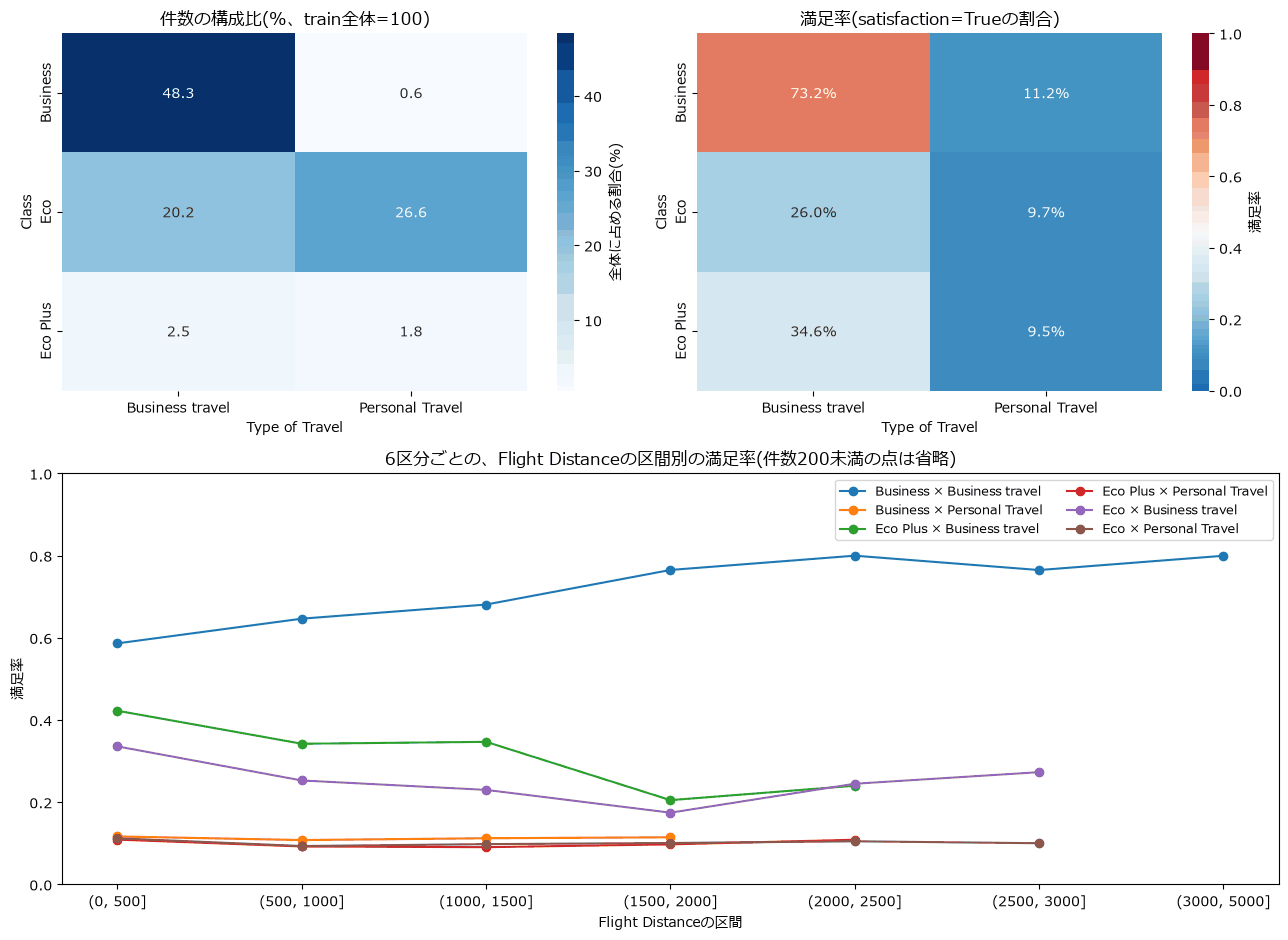

In [5]:
# Class× Type of Travelの6区分ごとに、件数の構成比と満足率を並べる
fig = plt.figure(figsize=(13, 9.5))
gs = fig.add_gridspec(2, 2, height_ratios=[1, 1.15])
ax_n, ax_r, ax_d = fig.add_subplot(gs[0, 0]), fig.add_subplot(gs[0, 1]), fig.add_subplot(gs[1, :])
share = pd.crosstab(train["Class"], train["Type of Travel"], normalize=True) * 100
rate = pd.crosstab(train["Class"], train["Type of Travel"], values=train[TARGET], aggfunc="mean")
sns.heatmap(share, annot=True, fmt=".1f", cmap="Blues", cbar_kws={"label": "全体に占める割合(%)"}, ax=ax_n)
ax_n.set_title("件数の構成比(%、train全体=100)")
sns.heatmap(rate, annot=True, fmt=".1%", cmap="RdBu_r", center=train[TARGET].mean(), vmin=0, vmax=1,
            cbar_kws={"label": "満足率"}, ax=ax_r)
ax_r.set_title("満足率(satisfaction=Trueの割合)")

# 1節で見えた「長距離ほど満足」が、6区分の中でも成り立つかを確認する
bins = [0, 500, 1000, 1500, 2000, 2500, 3000, 5000]
d = train.assign(dist=pd.cut(train["Flight Distance"], bins), seg=train["Class"] + " × " + train["Type of Travel"])
line = d.groupby(["seg", "dist"], observed=True)[TARGET].agg(["mean", "size"]).reset_index()
line = line[line["size"] >= 200]  # 件数が少なく揺れの大きい点は描かない
for seg, g in line.groupby("seg"):
    ax_d.plot(g["dist"].astype(str), g["mean"], marker="o", label=seg)
ax_d.set_xlabel("Flight Distanceの区間"); ax_d.set_ylabel("満足率"); ax_d.set_ylim(0, 1)
ax_d.set_title("6区分ごとの、Flight Distanceの区間別の満足率(件数200未満の点は省略)")
ax_d.legend(fontsize=9, ncol=2)
fig.tight_layout()
plt.show()

In [6]:
# 仮説の前提「出張かつビジネスクラスはFlight Distanceが長い」を確かめる: 6区分ごとのFlight Distanceの中央値と、1,500以上の乗客の内訳
segment = train["Type of Travel"] + " × " + train["Class"]
print("6区分ごとのFlight Distanceの中央値")
print(train.groupby(segment)["Flight Distance"].median().sort_values(ascending=False).to_string())
is_long = train["Flight Distance"] >= 1500
print()
print("Flight Distance1,500以上の乗客の内訳(%)")
print((segment[is_long].value_counts(normalize=True) * 100).round(1).to_string())

6区分ごとのFlight Distanceの中央値
Business travel × Business    1747.0
Personal Travel × Business     821.0
Personal Travel × Eco          759.0
Business travel × Eco          746.0
Personal Travel × Eco Plus     744.0
Business travel × Eco Plus     719.0

Flight Distance1,500以上の乗客の内訳(%)
Business travel × Business    88.1
Personal Travel × Eco          7.6
Business travel × Eco          2.9
Business travel × Eco Plus     0.6
Personal Travel × Eco Plus     0.5
Personal Travel × Business     0.3


#### ④ 考察・次のアクション
- **読み取れること:**
  - 出張かつビジネスクラスはFlight Distanceが長い。中央値は1,747で、ほかの5区分(719〜821)の2倍以上。Flight Distance 1,500以上の乗客の88.1%が、出張かつビジネスクラスだった。
  - 満足率が高いのは「出張でビジネスクラス」(73.2%)だけ。私用旅行は、Classに関係なく9.5〜11.2%。
  - 全体では0.696だったFlight Distanceの単変量AUCが、6区分の中では0.44〜0.59に下がる。エコノミーの出張客では、逆に長距離ほど満足率が下がる。
- **仮説は正しかったか:** 正しかった。Flight Distanceの効き目の多くは、客層の違いの表れだった。
- **次のアクション:**
  - 私用客はClass・Flight Distanceに関係なく、満足率が約10%とほぼ一定だった。評価の点数ごとに集計しても同じだった(評価ごとの一覧は4節)。そこで「評価が効くのは出張客だけ」と考え、出張客だけに値を持たせる特徴量を作った(ゲート特徴量: 出張客の快適さ・出張客のOn-board service。採用、+0.000063・+0.000045)。
  - Flight Distance×Classごとの満足率も特徴量にした(採用、改善は+0.000060と小さい)。なお、最大の改善になったFlight Distanceの値ごとの満足率(Target Encoding)は、EDAではなく学習前の事前確認から着想した。
  - 4節で、Type of Travel以外の客層(Class・Customer Type)でも、評価の効き方が変わるかを確かめる。

## 4節 ゲート(Customer Type・Type of Travel・Class)× 変数の満足率ヒートマップ

#### ① 目的・仮説
- **確認したいこと(仮説①の続き):** 3節から作ったゲート特徴量(出張客だけに評価の値を持たせる特徴量)は、特徴量エンジニアリングで効いた。ClassやCustomer Typeでも、評価の効き方が変わるのではないか。
- **なぜ必要か:** 評価が効かない客層がほかにもあれば、同じ作り方の特徴量を増やせる。
- **想定する結果:** 私用客と同じように、評価が効かない客層がほかにもある。

#### ② 検証方法
- **データ:** train。
- **方法:** 客の種類(Type of Travel・Class・Customer Type)ごとに、特徴量の値ごとの満足率を一覧にしたヒートマップで見る。

#### ③ コード・実行結果

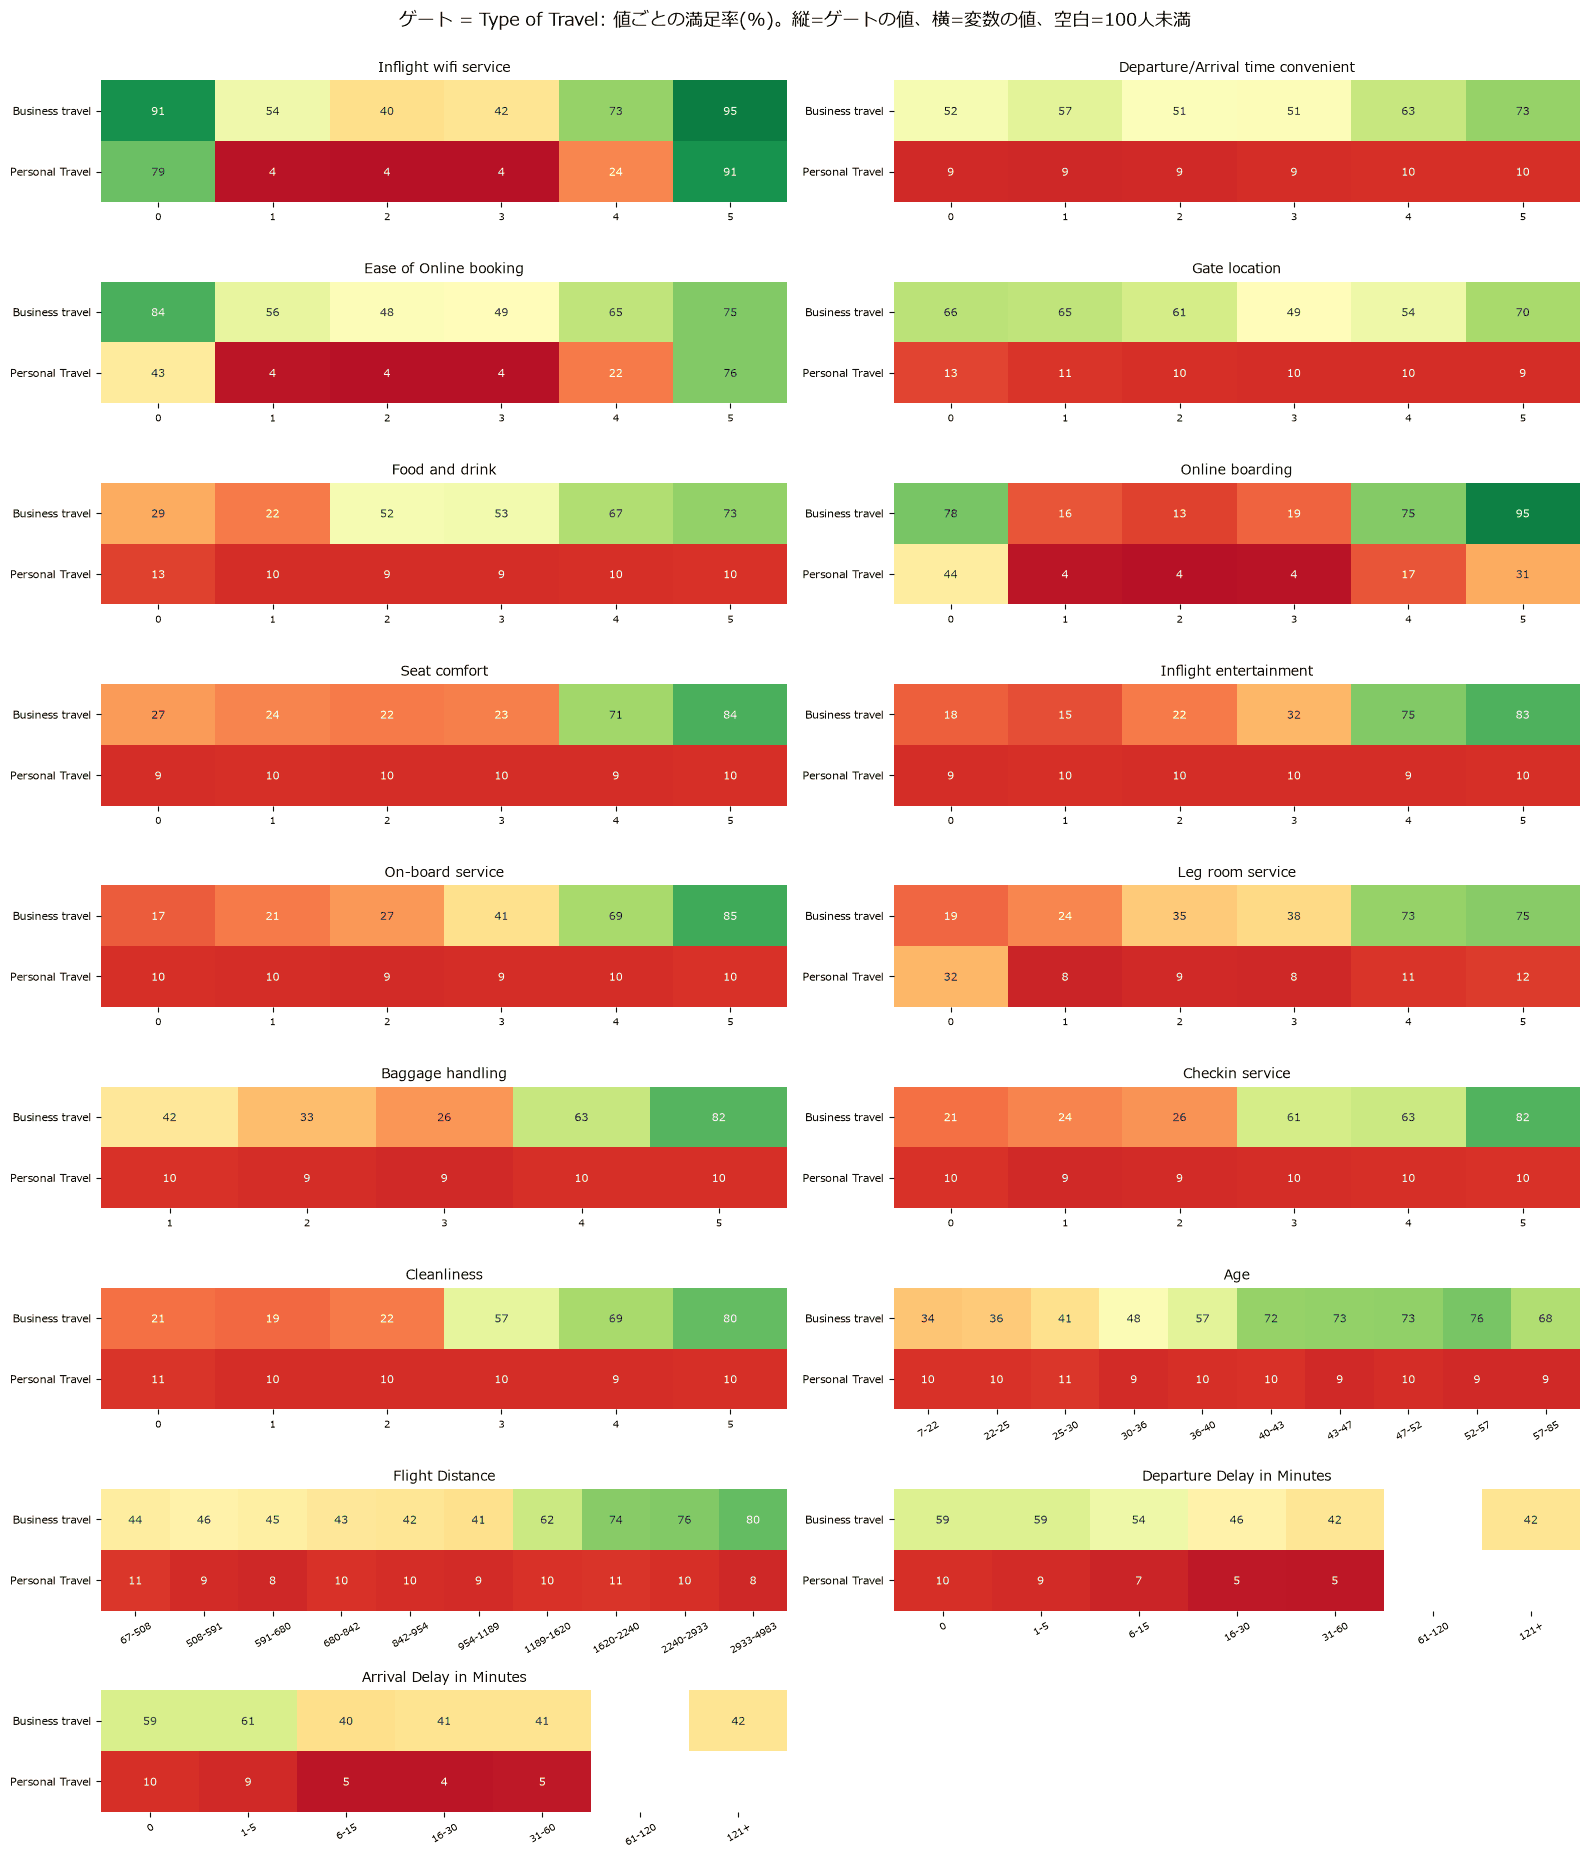

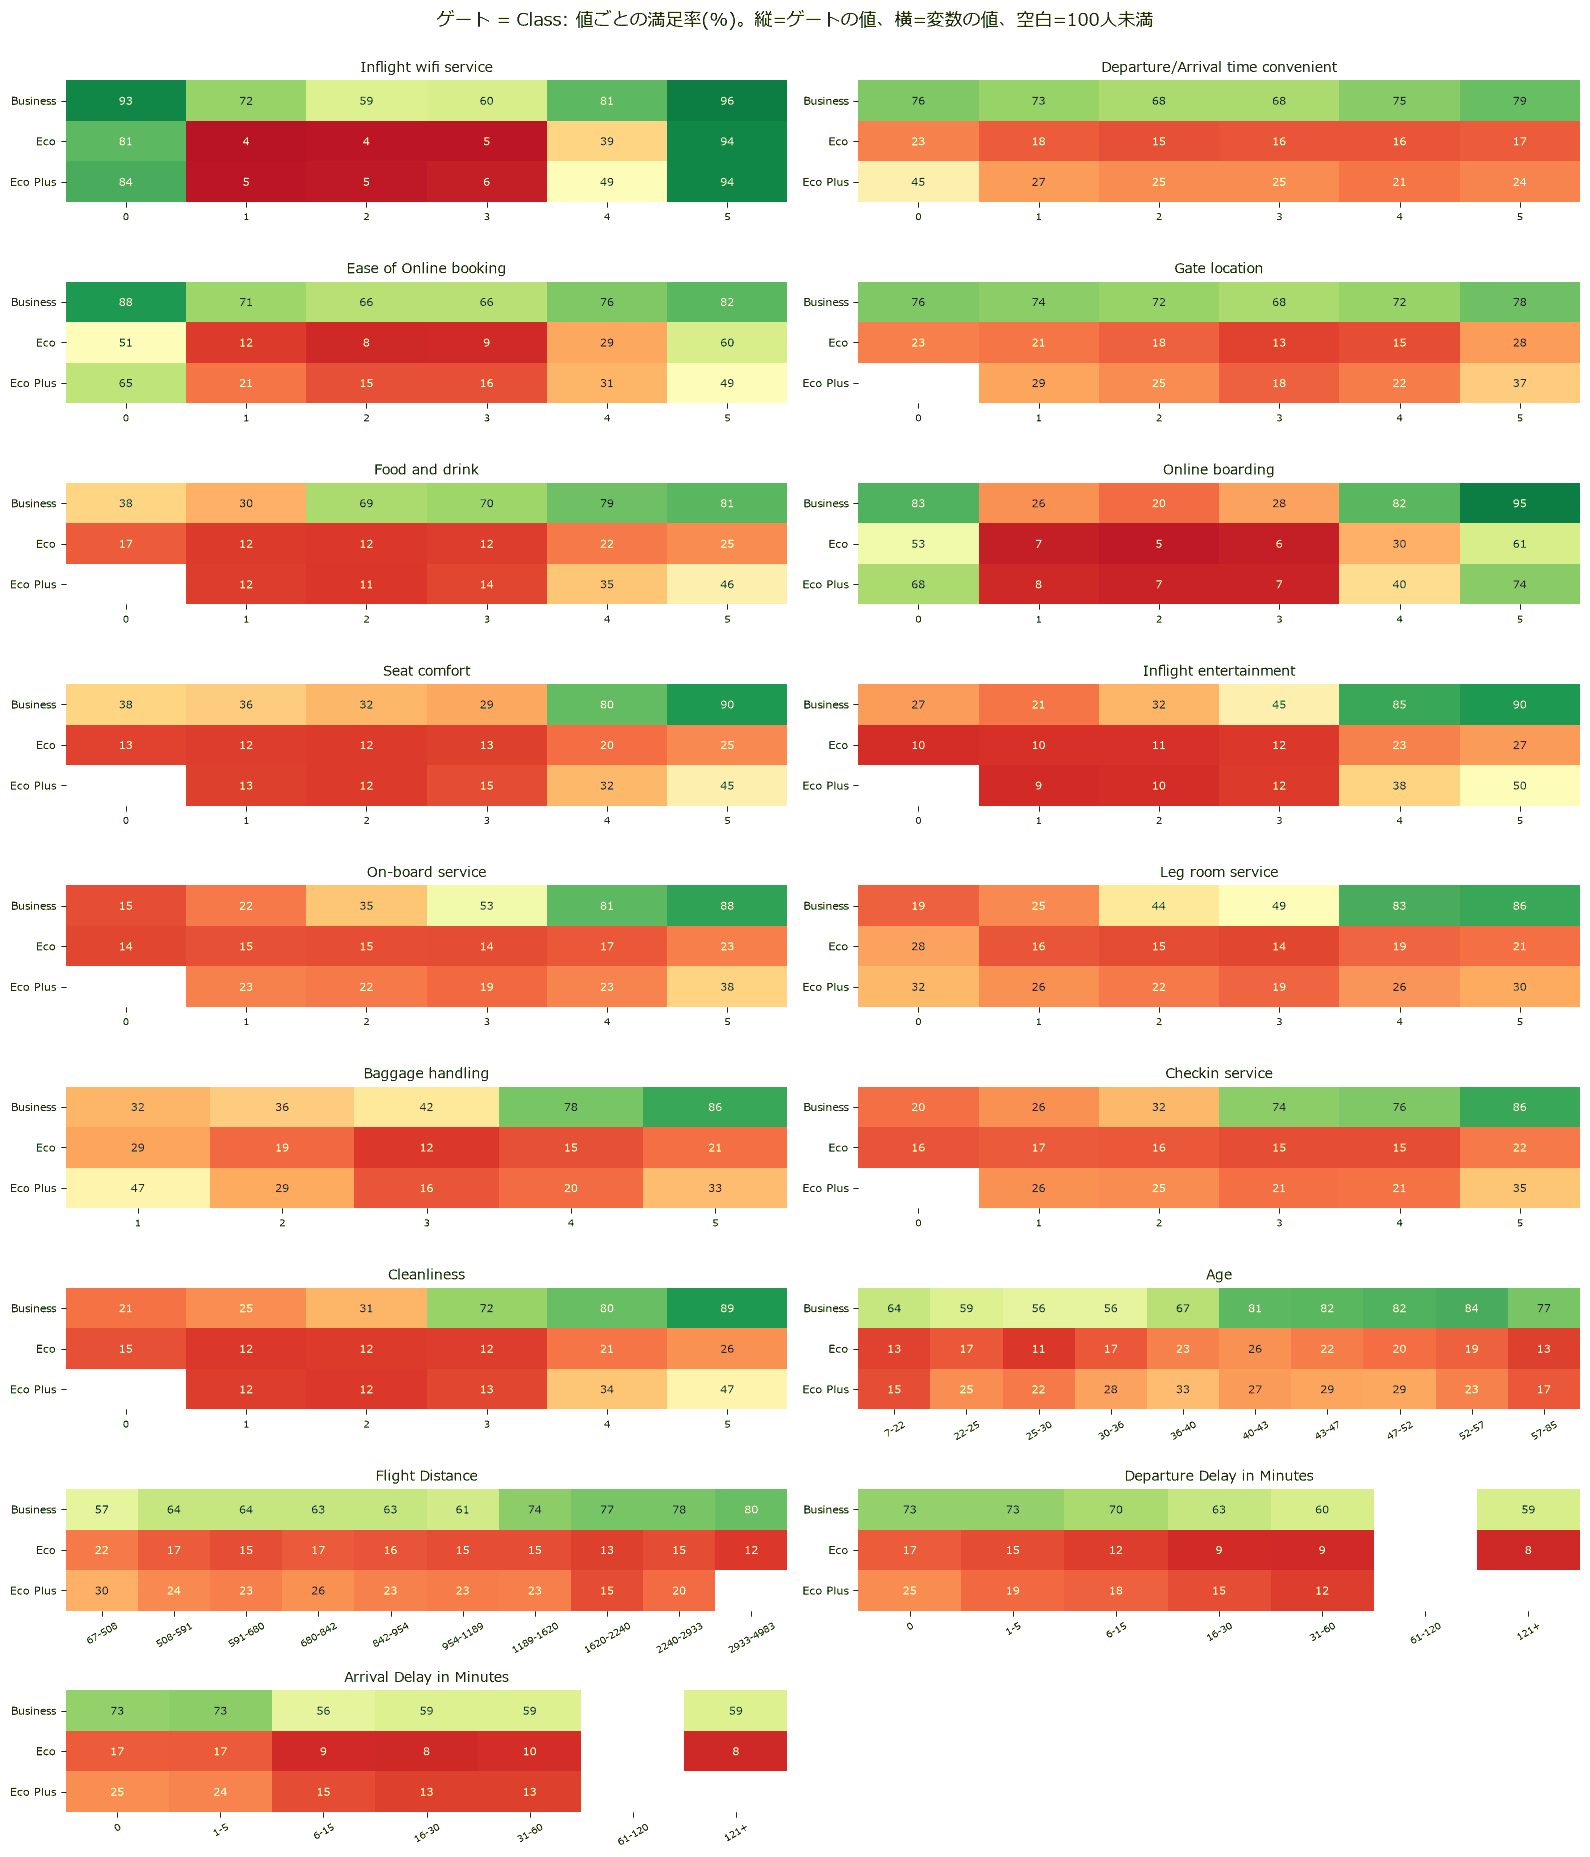

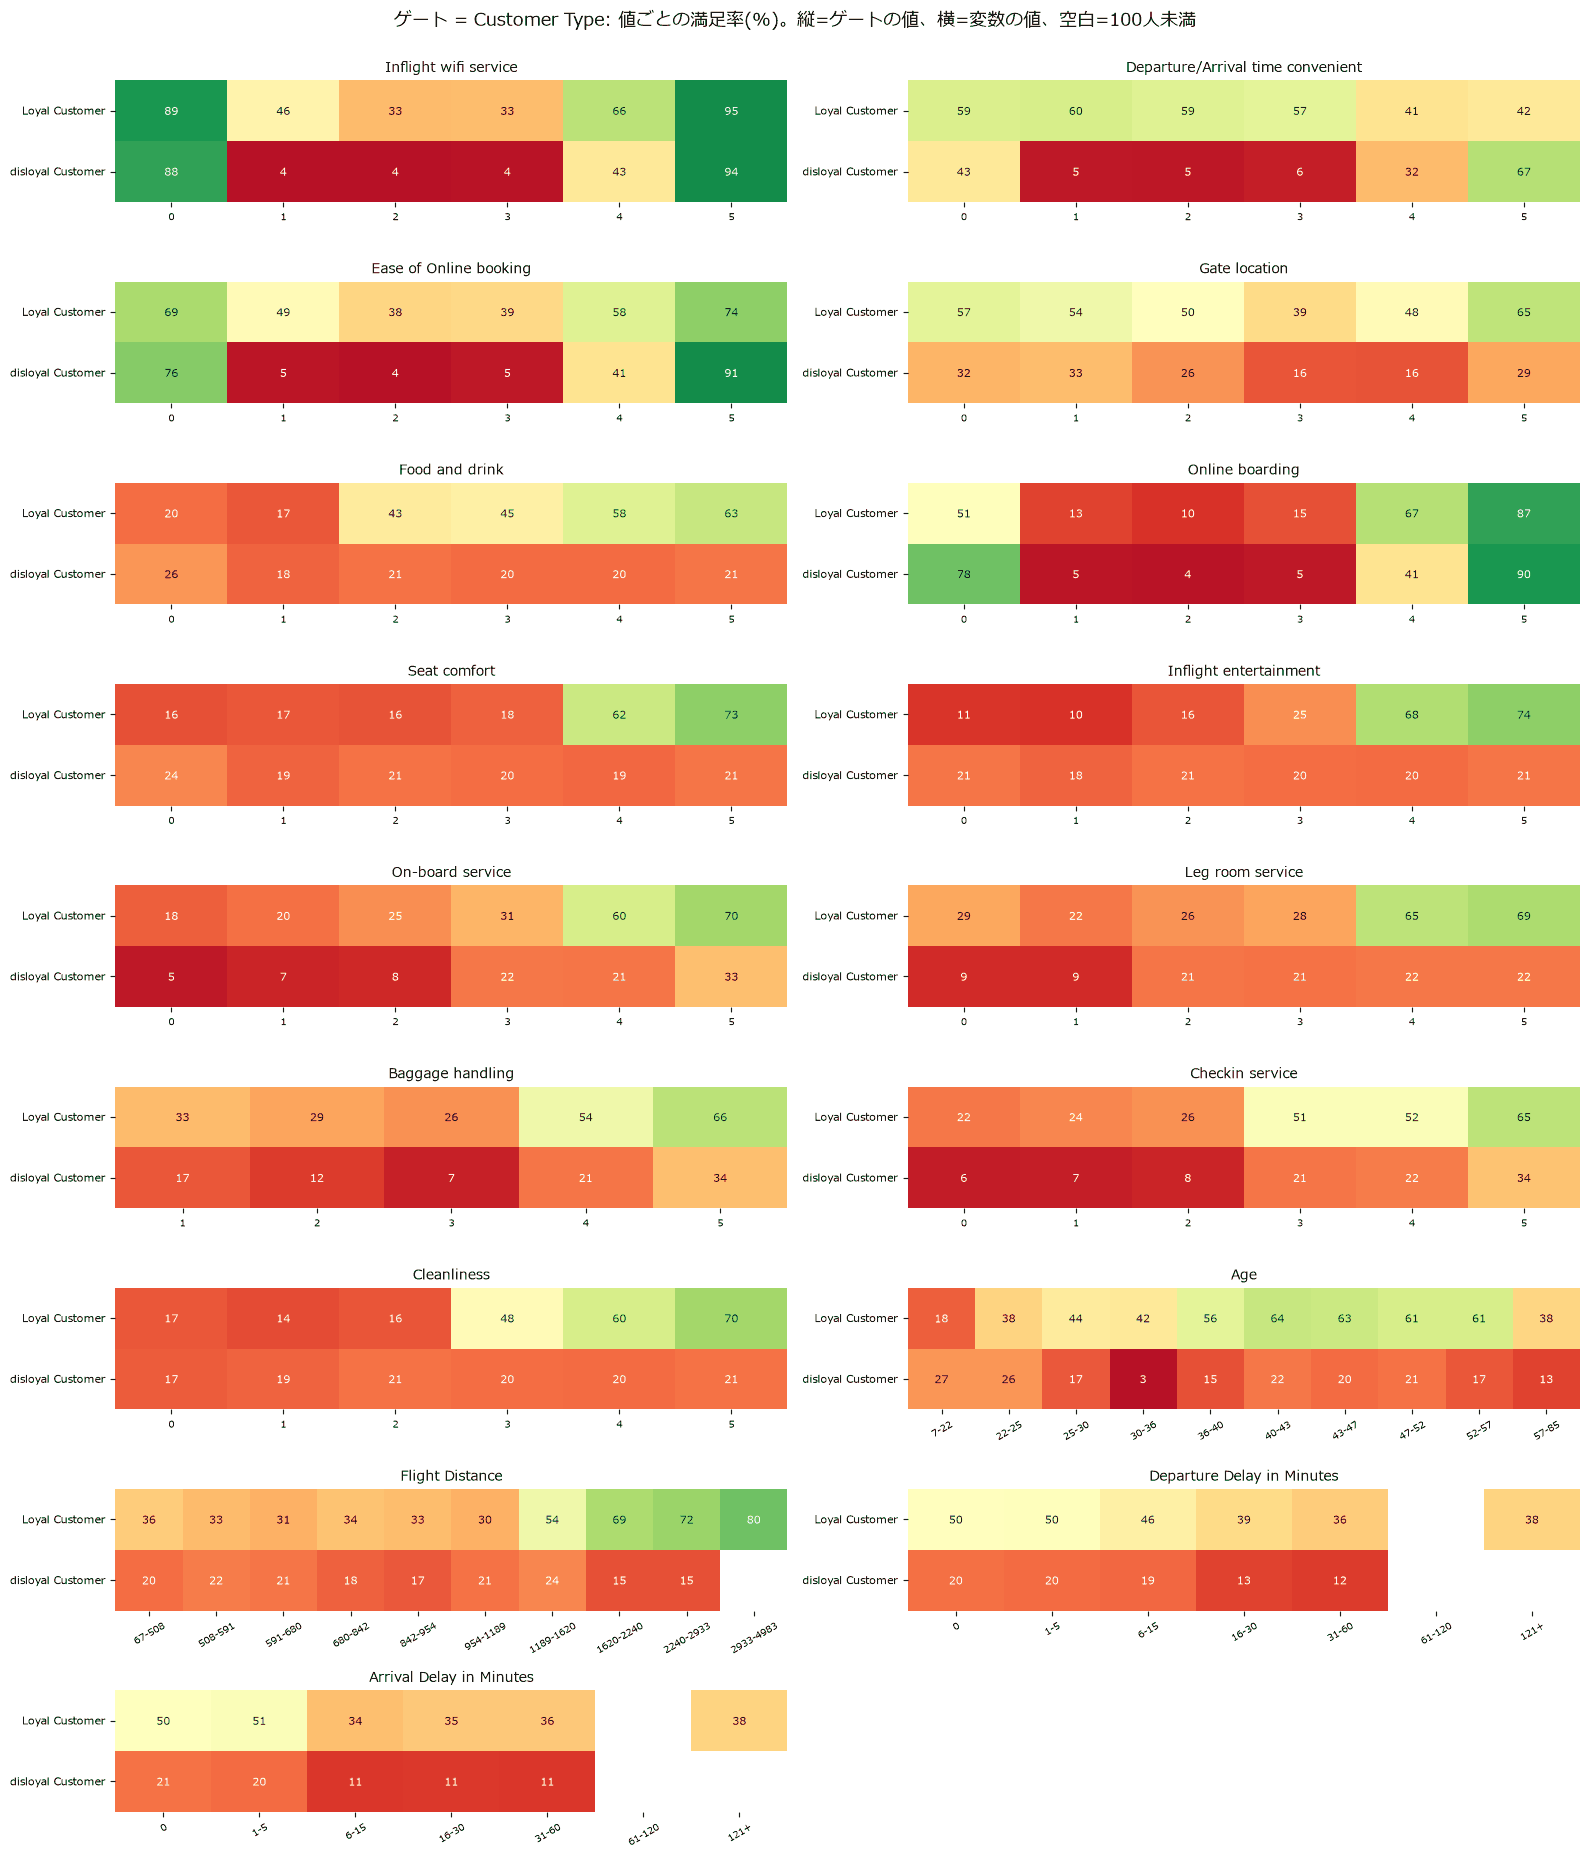

== Type of Travel ==
                               変数  Business travel  Personal Travel  最大-最小
           Inflight entertainment            0.787            0.501  0.285
                     Seat comfort            0.778            0.501  0.276
                 On-board service            0.759            0.509  0.250
                      Cleanliness            0.732            0.502  0.230
                 Baggage handling            0.720            0.509  0.211
                  Online boarding            0.859            0.661  0.198
                              Age            0.672            0.481  0.191
                  Checkin service            0.701            0.514  0.187
                  Flight Distance            0.671            0.499  0.172
                 Leg room service            0.705            0.534  0.171
                   Food and drink            0.645            0.507  0.138
           Ease of Online booking            0.575            0.686  0.110
Depa

In [7]:
# ゲート(Customer Type・Type of Travel・Class)× 変数1つで満足率のヒートマップを描く。
# 縦軸 = ゲートの値、横軸 = 変数の値(連続値は区間に分ける)、色・数字 = そのマスの満足率(%)。
# 同じ列の中で縦に色が大きく違う変数ほど「ゲートの値によって効き方が変わる」= ゲート特徴量の候補
def to_bins(c):
    x = train[c]
    if c in SVC:
        return x
    if c in ("Age", "Flight Distance"):
        return pd.qcut(x, 10, duplicates="drop").map(lambda iv: f"{iv.left:.0f}-{iv.right:.0f}")
    # 遅延は0分が半数以上を占めるので、0分と遅延の長さで区切る
    edges = [-1, 0, 5, 15, 30, 60, 120, np.inf]
    labels = ["0", "1-5", "6-15", "16-30", "31-60", "61-120", "121+"]
    return pd.cut(x.fillna(0), edges, labels=labels)

VARS = SVC + NUM
yv = train[TARGET].astype(int)
for g in ["Type of Travel", "Class", "Customer Type"]:
    fig, axes = plt.subplots(9, 2, figsize=(16, 2.1 * 9))
    for ax, c in zip(axes.flat, VARS):
        b = to_bins(c)
        rate = yv.groupby([train[g], b], observed=True).mean().unstack() * 100
        n = yv.groupby([train[g], b], observed=True).size().unstack()
        rate = rate.where(n >= 100)  # 100人未満のマスは率がぶれるので表示しない
        sns.heatmap(rate, ax=ax, cmap="RdYlGn", vmin=0, vmax=100, annot=True, fmt=".0f", cbar=False,
                    annot_kws={"size": 8})
        ax.set_title(c, fontsize=10)
        ax.set_xlabel("")
        ax.set_ylabel("")
        ax.tick_params(axis="x", labelsize=7, rotation=0 if c in SVC else 30)
        ax.tick_params(axis="y", labelsize=8, rotation=0)
    axes.flat[-1].axis("off")
    fig.suptitle(f"ゲート = {g}: 値ごとの満足率(%)。縦=ゲートの値、横=変数の値、空白=100人未満", fontsize=13)
    fig.tight_layout(rect=[0, 0, 1, 0.98])
    plt.show()

# 数値の要約: ゲートの値ごとに、変数1つで満足・不満をどれだけ見分けられるか(単変量AUC、元の値)
from sklearn.metrics import roc_auc_score
rows = []
for g in ["Type of Travel", "Class", "Customer Type"]:
    for c in VARS:
        r = {"ゲート": g, "変数": c}
        for v in sorted(train[g].unique()):
            m = train[g] == v
            r[v] = roc_auc_score(yv[m], train.loc[m, c].fillna(0))
        vals = [r[v] for v in sorted(train[g].unique())]
        r["最大-最小"] = max(vals) - min(vals)
        rows.append(r)
summary = pd.DataFrame(rows)
for g, d in summary.groupby("ゲート", sort=False):
    print(f"== {g} ==")
    print(d.drop(columns="ゲート").dropna(axis=1, how="all").sort_values("最大-最小", ascending=False).round(3).to_string(index=False))

#### ④ 考察・次のアクション
- **読み取れること:**
  - 出張客は、Inflight entertainment・Seat comfortなどの評価が4〜5点で満足率70〜85%に上がる。私用客は点数に関係なく約10%(単変量AUCは0.72〜0.79に対し0.50〜0.51)。
  - 常連でない客(ほぼ全員が出張客)では、快適さの評価はどの点数でも満足率約20%で、効かない。逆に、Inflight wifi service・Ease of Online bookingは強く効く。
- **仮説は正しかったか:** 正しかった。Customer Typeでも、評価の効き方が変わった。
- **次のアクション:** 「常連かつ出張客」だけに快適さの値を持たせる特徴量を作った(SHAP(予測への寄与)で1位)。ゲートなしの同じ特徴量は効かず、ゲートありとの直接比較で改善したので、効果はゲートによるものと確かめた。

## 5節 サービス評価(0〜5)× 満足度(箱ひげ図・ヒストグラム)

#### ① 目的・仮説
- **確認したいこと:** サービス評価13項目のうち、どれが満足度と強く結びついているか。点数ごとの満足率がどう変わるか。
- **なぜ必要か:** 点数と満足率の関係の形(段差・U字型)は、特徴量の作り方の手がかりになる。
- **想定する結果:** どの項目も、点数が高いほど満足率が上がる。

#### ② 検証方法
- **データ:** train。
- **方法:** 1節と同じ箱ひげ図と分布を、13項目について並べる(評価は0〜5点)。

#### ③ コード・実行結果

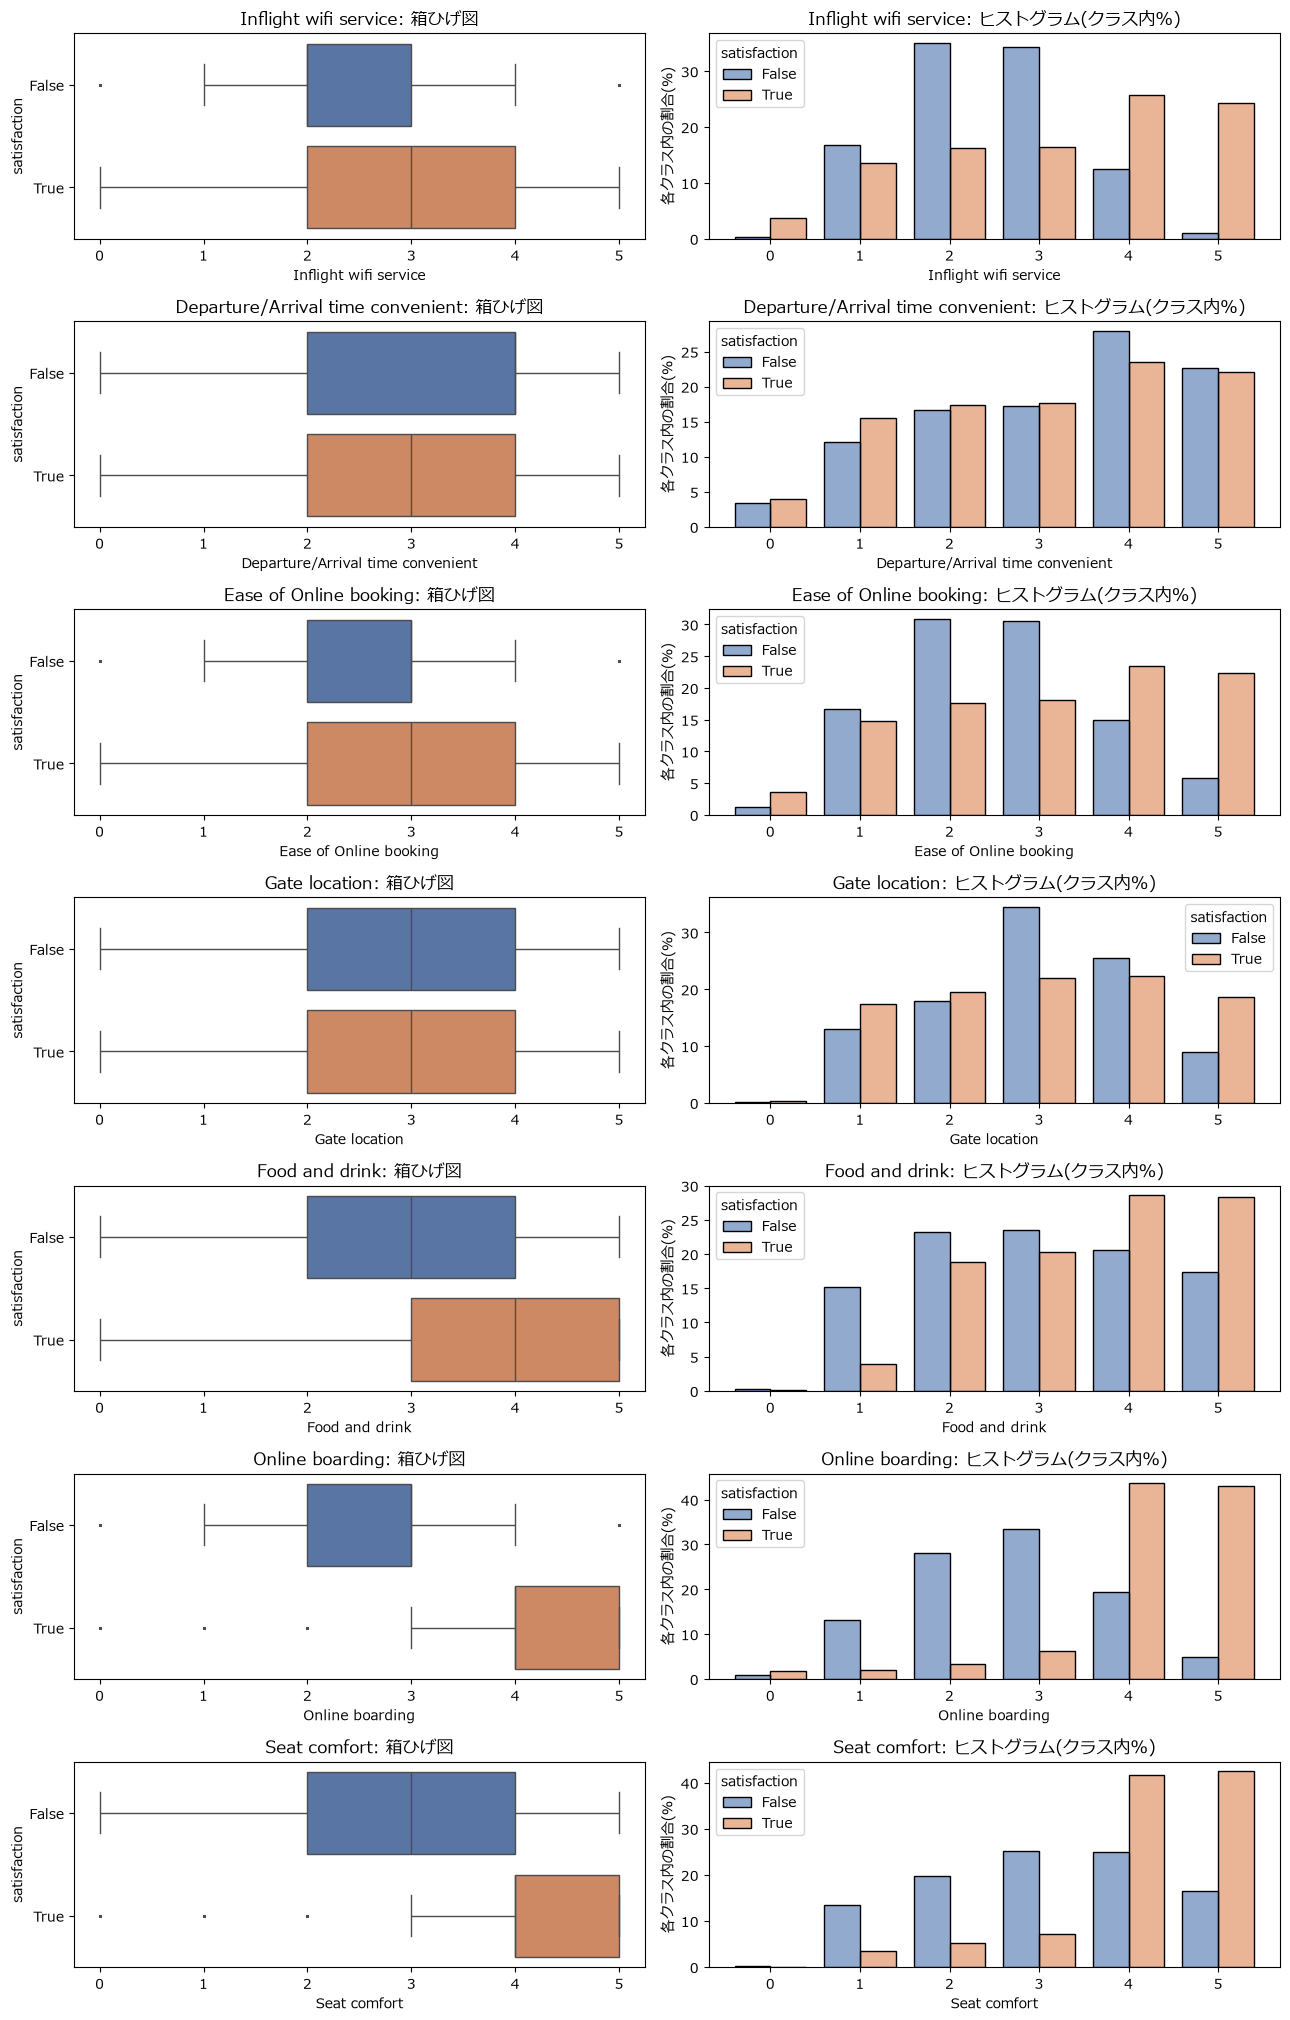

In [8]:
box_hist(SVC[:7], discrete=SVC)

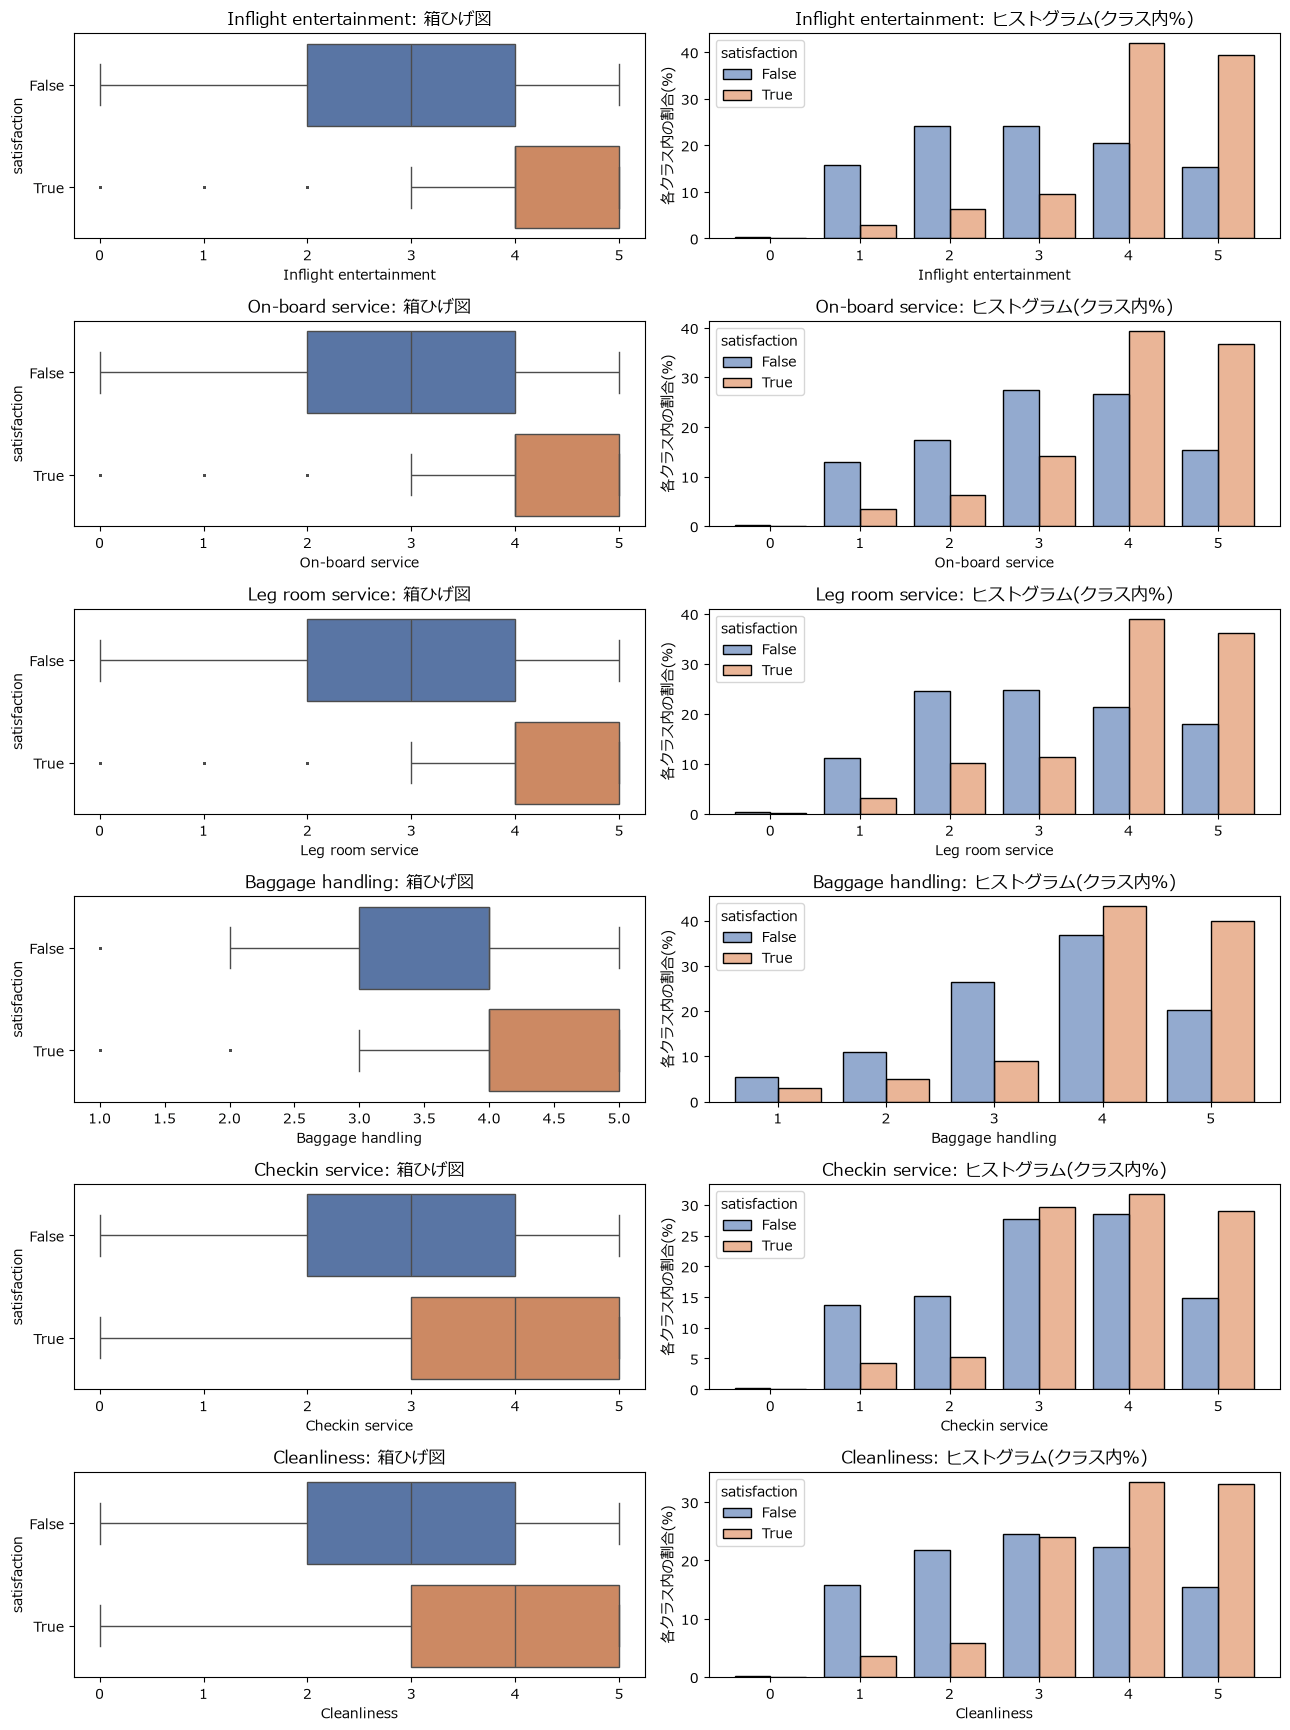

In [9]:
box_hist(SVC[7:], discrete=SVC)

#### ④ 考察・次のアクション
- **読み取れること:**
  - 最も強いのはOnline boarding(AUC 0.840)。1〜3点の満足率は9〜13%だが、4点で64%、5点で88%に跳ね上がる。Seat comfort・Inflight entertainment・Cleanlinessなども、「4点以上かどうか」の段差が大きい。
  - Inflight wifi service・Ease of Online bookingは**U字型**だった。Inflight wifi serviceの満足率は0点で89%、1点で39%、2〜3点で27%、5点で95%。
  - Departure/Arrival time convenientだけは、評価が高いほど満足率がわずかに下がる(AUC 0.473)。
- **想定との比較:** 多くの項目は想定どおりだった。Inflight wifi service・Ease of Online bookingの0点と、Departure/Arrival time convenientは想定と違った。
- **次のアクション:** Inflight wifi service・Ease of Online bookingの0点は、最低評価ではなく「使っていない(評価なし)」ではないか(仮説②)。6節で確かめる。

## 6節 サービス評価0の意味(悪い評価か、未回答・該当なしか)

#### ① 目的・仮説
- **確認したいこと(仮説②):** 5節で、Inflight wifi service・Ease of Online bookingは0点の満足率が高かった(U字型)。0点は最低評価ではなく、「使っていない(評価なし)」ではないか。ほかに0点が多い項目はどれで、その0点はどちらの意味か。
- **なぜ必要か:** 0点が「評価なし」なら、点数として扱うのではなく、「評価なし」の印を特徴量にした方が効く可能性がある。
- **想定する結果:** 0点が多いのは、使わない人がいるサービス(Inflight wifi service・Ease of Online bookingなど)。その0点の人は、1点の人より満足率が高く、ほかの項目の評価も高い。

#### ② 検証方法
- **データ:** trainとtest、ベースライン(00)のOOF(各行を、その行を学習していないモデルで予測した値。`data/oof_lightgbm_baseline.npy`)。
- **方法:**
  1. 項目ごとの0点の割合をtrainとtestで比べ、0点が多い項目を絞る。
  2. 項目ごとに、0点・1点・5点の人の満足率と、その人がほかの項目に付けた評価の平均を比べる。0点の人について、ベースラインの予測と実際の満足率の差も見る。

#### ③ コード・実行結果

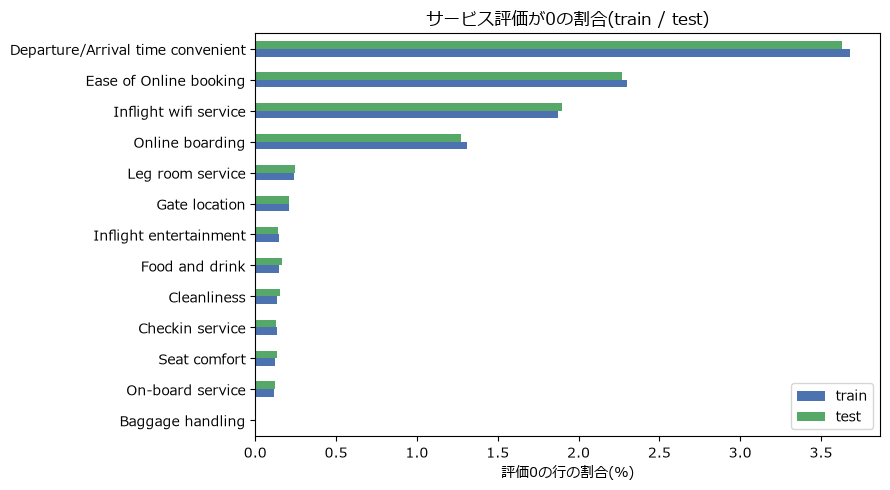

いずれかの評価が0点の行: train 6.4% / test 6.4%


In [10]:
test = pd.read_csv("../data/test.csv")
# 項目ごとの0点の割合をtrainとtestで並べ、0点が多い項目を絞る
fig, ax = plt.subplots(figsize=(9, 5))
z = pd.DataFrame({"train": (train[SVC] == 0).mean() * 100, "test": (test[SVC] == 0).mean() * 100})
z.sort_values("train").plot.barh(ax=ax, color=["#4C72B0", "#55A868"])
ax.set_xlabel("評価0の行の割合(%)"); ax.set_title("サービス評価が0の割合(train / test)")
fig.tight_layout()
plt.show()
print(f"いずれかの評価が0点の行: train {(train[SVC] == 0).any(axis=1).mean():.1%} / test {(test[SVC] == 0).any(axis=1).mean():.1%}")

                                      n0   sat0   sat1   sat5  other0  other1  \
item                                                                            
Inflight entertainment              1020  0.140  0.127  0.671   2.561   2.553   
On-board service                     801  0.147  0.174  0.657   2.897   2.858   
Cleanliness                          945  0.168  0.155  0.630   2.625   2.627   
Checkin service                      929  0.179  0.199  0.610   2.954   2.932   
Seat comfort                         838  0.184  0.174  0.671   2.671   2.637   
Food and drink                      1014  0.219  0.171  0.565   2.669   2.640   
Leg room service                    1693  0.270  0.189  0.615   3.028   2.879   
Departure/Arrival time convenient  25751  0.478  0.506  0.437   3.262   3.006   
Gate location                       1455  0.543  0.514  0.625   3.207   3.193   
Online boarding                     9147  0.620  0.105  0.875   3.216   2.767   
Ease of Online booking      

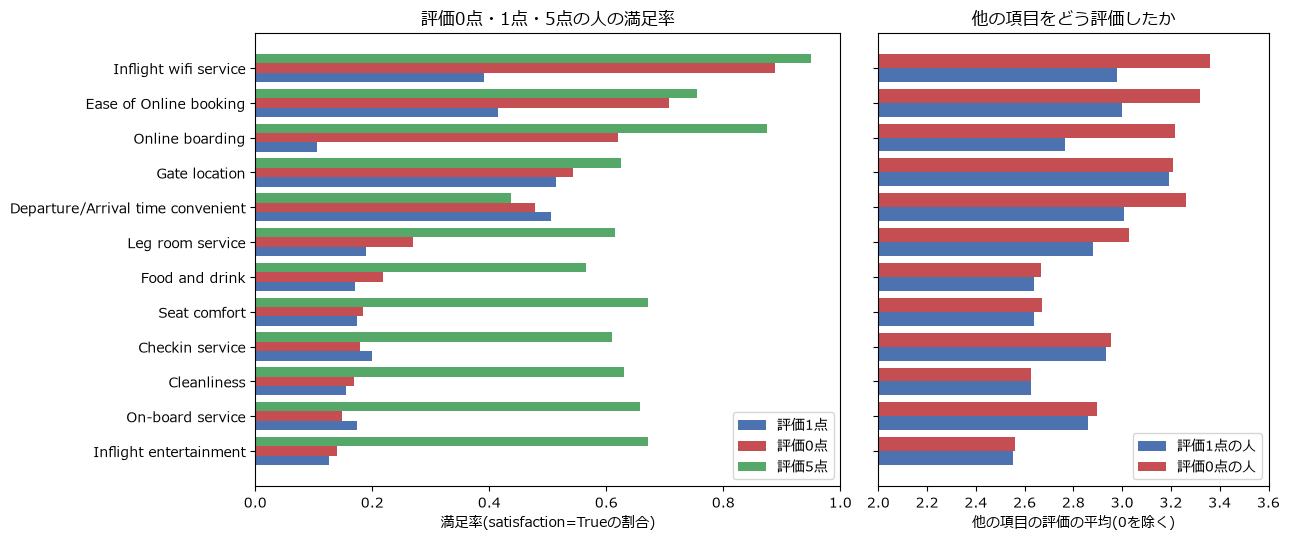

In [11]:
# サービス評価の0は「悪い評価」か「未回答・該当なし」か。0点の人を1点・5点の人と比べる
# 0=悪い評価なら、0点の人は1点の人と似る(満足率が低い・他の項目の評価も低い)はず
items = [c for c in SVC if (train[c] == 0).any()]  # 0が1件も無いBaggage handlingは除く
oof = np.load("../data/oof_lightgbm_baseline.npy")  # ベースライン(LightGBM、元の特徴量20個)のOOF予測。00_baselineで作る
yv = train[TARGET].astype(int)
rows = []
for c in items:
    others = [o for o in SVC if o != c]
    other_avg = train[others].replace(0, np.nan).mean(axis=1)  # 他の項目の平均(0は除いて計算)
    z = train[c] == 0
    rows.append({"item": c, "n0": int(z.sum()),
                 "sat0": yv[z].mean(), "sat1": yv[train[c] == 1].mean(), "sat5": yv[train[c] == 5].mean(),
                 "other0": other_avg[z].mean(), "other1": other_avg[train[c] == 1].mean(),
                 "resid0": (yv[z] - oof[z]).mean()})  # 実際の満足率 - 予測確率の平均(0に近いほどモデルが正しく見積もれている)
zero = pd.DataFrame(rows).set_index("item").sort_values("sat0")
print(zero.round(3))

fig, (ax0, ax1) = plt.subplots(1, 2, figsize=(13, 5.5), gridspec_kw={"width_ratios": [1.5, 1]})
yy = np.arange(len(zero))
for off, col, lab, color in [(-0.27, "sat1", "評価1点", "#4C72B0"), (0, "sat0", "評価0点", "#C44E52"),
                              (0.27, "sat5", "評価5点", "#55A868")]:
    ax0.barh(yy + off, zero[col], height=0.27, color=color, label=lab)
ax0.set_yticks(yy, zero.index); ax0.set_xlim(0, 1); ax0.set_xlabel("満足率(satisfaction=Trueの割合)")
ax0.set_title("評価0点・1点・5点の人の満足率"); ax0.legend(loc="lower right")
ax1.barh(yy - 0.2, zero["other1"], height=0.4, color="#4C72B0", label="評価1点の人")
ax1.barh(yy + 0.2, zero["other0"], height=0.4, color="#C44E52", label="評価0点の人")
ax1.set_yticks(yy, []); ax1.set_xlim(2, 3.6); ax1.set_xlabel("他の項目の評価の平均(0を除く)")
ax1.set_title("他の項目をどう評価したか"); ax1.legend(loc="lower right")
fig.tight_layout()
plt.show()

#### ④ 考察・次のアクション
- **読み取れること:**
  - 0点が多いのは、Departure/Arrival time convenient 3.7%・Ease of Online booking 2.3%・Inflight wifi service 1.9%・Online boarding 1.3%の4項目。ほかの9項目は0.3%未満。いずれかの評価が0点の行は6.4%で、trainとtestで割合は同じ。
  - Inflight wifi service・Ease of Online booking・Online boardingは、0点の満足率(89%・71%・62%)が1点の満足率(39%・42%・11%)よりずっと高い。
  - 一方、Seat comfort・Food and drinkなどは0点と1点の満足率がほぼ同じで、0点は最低評価として使われている。0点が最も多いDeparture/Arrival time convenientも、0点と1点の満足率が47.8%・50.6%とほぼ同じだった。
- **仮説は正しかったか:** 一部の項目でだけ正しかった。Inflight wifi service・Ease of Online booking・Online boardingの0点は「使っていないので評価なし」と考えられるが、0点の意味は項目で違う。
- **次のアクション(結果):**
  - 項目ごとの0点の印を特徴量にしたが、効かなかった。木は「評価≦0.5」の1回の分岐で0点の人を切り出せ、0点の人の満足率もすでに正しく見積もれていた(予測と実際の差が±0.005)。
  - 複数の項目にまたがる「0点の個数」は1回の分岐では作れないので試した。1seedではわずかに効いた(+0.00001)が、3通りの分け方で確かめ直すと基準に届かず外した。